# 09 — Frozen final Test evaluation

This notebook refits the configurations selected in notebooks 01–08 on the
1913 observed Train+Validation days, then forecasts d_1914–d_1941 from one
origin. The benchmark contains 12 configurations from 11 model families,
including both Moving Average windows.

The protocol and Validation-selected configurations are embedded below.
Known future calendar fields are loaded separately. The complete forecast
table is saved and hashed before Test sales labels are loaded for scoring.
Use the same processed Kaggle dataset and CPU.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from importlib import metadata
from time import perf_counter
from zipfile import ZipFile, ZIP_DEFLATED
import hashlib
import json
import platform
import random
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from statsmodels.tsa.arima.model import ARIMA
from threadpoolctl import threadpool_limits
import xgboost as xgb

DATA_DIR = None
OUTPUT_DIR = None
HORIZON = 28
SEASON_LENGTH = 7
MA_WINDOWS = (7, 28)
SALES_SCALE = 1000.0
MAX_ITERATIONS = (200, 400)
ORIGIN = 1913
SEED = 42

LAGS = (28, 35, 42, 56)
ROLLING_SHIFT = 28
ROLLING_WINDOWS = (7, 28, 56)
EXOG_COLUMNS = ['wday_iso','month','event_name_1','event_name_2','snap_CA','snap_TX','snap_WI']

BATCH_SIZE = 256
LAYERS = 2
DROPOUT = 0.2
LEARNING_RATE = 0.003
LR_STEP = 15
LR_GAMMA = 0.5
HUBER_DELTA = 0.05
MAX_EPOCHS = 40
PATIENCE = 8
CPU_THREADS = 2
torch.set_num_threads(CPU_THREADS)
torch.use_deterministic_algorithms(True)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
RUN_STARTED = perf_counter()

In [2]:
FROZEN_PROTOCOL = {'protocol_version': 1, 'forecast_origin_day': 1913, 'horizon': 28, 'forecast_start': '2016-04-25', 'forecast_end': '2016-05-22', 'training_history': 'Train+Validation, d_1 through d_1913', 'rmsse_scale': 'mean squared first difference of the full 1913-day observed history', 'selected_before_test': 'svr_07__lags_calendar_events_snap', 'plot_models_selected_before_test': ['svr_07__lags_calendar_events_snap', 'xgb_lags_calendar_events_snap_trial_022', 'sarima_1_1_1_1_1_1_7_n__calendar_events_snap'], 'models': [{'model': 'Naive', 'config_id': 'naive', 'kind': 'baseline', 'params': {'model': 'Naive', 'window': 0, 'season_length': 0}}, {'model': 'Seasonal Naive', 'config_id': 'seasonal_naive_7', 'kind': 'baseline', 'params': {'model': 'Seasonal Naive', 'window': 0, 'season_length': 7}}, {'model': 'Moving Average', 'config_id': 'moving_average_7', 'kind': 'baseline', 'params': {'model': 'Moving Average', 'window': 7, 'season_length': 0}}, {'model': 'Moving Average', 'config_id': 'moving_average_28', 'kind': 'baseline', 'params': {'model': 'Moving Average', 'window': 28, 'season_length': 0}}, {'model': 'ARIMA', 'config_id': 'arima_7_1_2_t', 'kind': 'statistical', 'params': {'family': 'ARIMA', 'config_id': 'arima_7_1_2_t', 'p': 7, 'd': 1, 'q': 2, 'P': 0, 'D': 0, 'Q': 0, 's': 0, 'trend': 't'}, 'feature_group': 'history_only'}, {'model': 'SARIMA', 'config_id': 'sarima_1_1_1_1_1_1_7_n', 'kind': 'statistical', 'params': {'family': 'SARIMA', 'config_id': 'sarima_1_1_1_1_1_1_7_n', 'p': 1, 'd': 1, 'q': 1, 'P': 1, 'D': 1, 'Q': 1, 's': 7, 'trend': 'n'}, 'feature_group': 'history_only'}, {'model': 'ARIMAX', 'config_id': 'arima_7_1_2_t__calendar_events_snap', 'kind': 'statistical', 'params': {'family': 'ARIMA', 'config_id': 'arima_7_1_2_t', 'p': 7, 'd': 1, 'q': 2, 'P': 0, 'D': 0, 'Q': 0, 's': 0, 'trend': 't'}, 'feature_group': 'calendar_events_snap'}, {'model': 'SARIMAX', 'config_id': 'sarima_1_1_1_1_1_1_7_n__calendar_events_snap', 'kind': 'statistical', 'params': {'family': 'SARIMA', 'config_id': 'sarima_1_1_1_1_1_1_7_n', 'p': 1, 'd': 1, 'q': 1, 'P': 1, 'D': 1, 'Q': 1, 's': 7, 'trend': 'n'}, 'feature_group': 'calendar_events_snap'}, {'model': 'SVR', 'config_id': 'svr_07__lags_calendar_events_snap', 'kind': 'tabular', 'params': {'C': 10.0, 'epsilon': 0.05, 'gamma': 0.01}, 'feature_group': 'lags_calendar_events_snap'}, {'model': 'Random Forest', 'config_id': 'rf_08__lags_calendar_events_snap', 'kind': 'tabular', 'params': {'max_depth': None, 'min_samples_leaf': 1, 'max_features': 0.7}, 'feature_group': 'lags_calendar_events_snap'}, {'model': 'XGBoost', 'config_id': 'xgb_lags_calendar_events_snap_trial_022', 'kind': 'xgboost', 'params': {'colsample_bytree': 0.6539276136962279, 'gamma': 1.1265521513726753, 'huber_slope': 5.0, 'learning_rate': 0.07413580977580514, 'max_depth': 2, 'min_child_weight': 1.7987416673320433, 'objective': 'reg:pseudohubererror', 'reg_alpha': 1.7552069629837823, 'reg_lambda': 0.9242356456770562, 'subsample': 0.7351521499999777}, 'tree_count': 402, 'feature_group': 'lags_calendar_events_snap'}, {'model': 'LSTM', 'config_id': 'lstm_w28_h32_mse', 'kind': 'lstm', 'params': {'config_id': 'lstm_w28_h32_mse', 'lookback': 28, 'hidden_size': 32, 'loss': 'mse'}, 'seed': 42, 'epoch_rule': {'optimizer': 'Adam', 'learning_rate': 0.003, 'batch_size': 256, 'lr_step': 15, 'lr_gamma': 0.5, 'huber_delta': 0.05, 'max_epochs': 40, 'patience': 8, 'inner_monitor_days': 28, 'epoch_rule': 'inner minimum RMSE, then fixed-epoch fit on full origin prefix', 'device': 'cpu', 'threads': 2}}], 'primary_seed': 42, 'lstm_epoch_rule': 'inner final 28 observed days select epoch, then reinitialize and refit on full history', 'labels_access_rule': 'write and hash all 336 forecasts before loading Test total_sales', 'fixed_training_settings': {'statistical': {'target_divisor': 1000, 'optimizer': 'lbfgs', 'max_iterations': [200, 400], 'method': 'statespace', 'cov_type': 'opg', 'enforce_stationarity': True, 'enforce_invertibility': True}, 'SVR': {'kernel': 'rbf', 'max_iter': 1000000, 'tol': 0.001, 'feature_scaler': 'StandardScaler', 'target_scaler': 'StandardScaler'}, 'Random Forest': {'n_estimators': 200, 'criterion': 'squared_error', 'bootstrap': True, 'min_samples_split': 2, 'random_state': 42, 'n_jobs': 1}, 'XGBoost': {'tree_method': 'hist', 'device': 'cpu', 'n_jobs': 1, 'random_state': 42, 'target_divisor': 1000, 'base_score_rule': 'usable training target mean in scaled units'}, 'LSTM': {'architecture': {'input_size': 1, 'num_layers': 2, 'hidden_size': 32, 'dropout': 0.2, 'head_outputs': 28}, 'training': {'optimizer': 'Adam', 'learning_rate': 0.003, 'batch_size': 256, 'lr_step': 15, 'lr_gamma': 0.5, 'huber_delta': 0.05, 'max_epochs': 40, 'patience': 8, 'inner_monitor_days': 28, 'epoch_rule': 'inner minimum RMSE, then fixed-epoch fit on full origin prefix', 'device': 'cpu', 'threads': 2}, 'seed': 42}}, 'source_artifact_sha256': {'tmp/arima_submitted_audit/04_Outputs_and_Artifacts/arima_selected_configurations.json': '5797feb363e751c3785068362ff37d13e768ccc9a7c5d5f60acb5c9cb77c99a8', 'tmp/arimax_submitted_audit/04_Outputs_and_Artifacts/exog_selected_configurations.json': '9250279df8a223acf5ed96d87a03c88f0a916b978524824f1d01ad77275a08fe', 'tmp/svr_rf_submitted_audit/04_Outputs_and_Artifacts/svr_rf_selected_configurations.json': '599f2670c86873c1d23e9d4b5610298c0880550d6f4f01b63bb5e71bf46bbc9b', 'tmp/xgboost_submitted_audit/04_Outputs_and_Artifacts/xgb_selected_configurations.json': '62eda920f01aa1670313cd4b6b67351e27dd06999fc7e6fa2cfb3aeba50ce621', 'tmp/lstm_submitted_audit/04_Outputs_and_Artifacts/lstm_selected_configuration.json': 'f5d8f8dc4d965c77d169afde69814a7f1b9f59029fe616d703825f759a04e8bf'}}

DEVELOPMENT_SELECTION = [{'model': 'SVR', 'config_id': 'svr_07__lags_calendar_events_snap', 'validation_rmsse': 0.2818139555154677, 'mean_rmsse': 0.5994398556872159, 'std_rmsse': 0.3125885514149348}, {'model': 'XGBoost', 'config_id': 'xgb_lags_calendar_events_snap_trial_022', 'validation_rmsse': 0.3183514504690523, 'mean_rmsse': 0.4222445706789847, 'std_rmsse': 0.0963944962959595}, {'model': 'SARIMAX', 'config_id': 'sarima_1_1_1_1_1_1_7_n__calendar_events_snap', 'validation_rmsse': 0.358913499433, 'mean_rmsse': 0.467884522232, 'std_rmsse': 0.151106334062}, {'model': 'ARIMAX', 'config_id': 'arima_7_1_2_t__calendar_events_snap', 'validation_rmsse': 0.376470511984, 'mean_rmsse': 0.492196004878, 'std_rmsse': 0.144294798138}, {'model': 'Random Forest', 'config_id': 'rf_08__lags_calendar_events_snap', 'validation_rmsse': 0.4857398004848055, 'mean_rmsse': 0.6107860180717435, 'std_rmsse': 0.1699458785392614}, {'model': 'SARIMA', 'config_id': 'sarima_1_1_1_1_1_1_7_n', 'validation_rmsse': 0.487335523332, 'mean_rmsse': 0.603016579708, 'std_rmsse': 0.170685772507}, {'model': 'ARIMA', 'config_id': 'arima_7_1_2_t', 'validation_rmsse': 0.598203196393, 'mean_rmsse': 0.603964905434, 'std_rmsse': 0.0169636102746}, {'model': 'Seasonal Naive', 'config_id': 'seasonal_naive_7', 'validation_rmsse': 0.667678997574433, 'mean_rmsse': 0.7518889268287978, 'std_rmsse': 0.1541812295923552}, {'model': 'Moving Average', 'config_id': 'moving_average_28', 'validation_rmsse': 1.200108159846032, 'mean_rmsse': 1.1642656303046075, 'std_rmsse': 0.0603277380488986}, {'model': 'Moving Average', 'config_id': 'moving_average_7', 'validation_rmsse': 1.2164900329969195, 'mean_rmsse': 1.2238115674010517, 'std_rmsse': 0.0532822379226507}, {'model': 'LSTM', 'config_id': 'lstm_w28_h32_mse', 'validation_rmsse': 1.301320387234729, 'mean_rmsse': 1.5192998095324146, 'std_rmsse': 0.1890404317983235}, {'model': 'Naive', 'config_id': 'naive', 'validation_rmsse': 1.3842651329036886, 'mean_rmsse': 1.7026938293883542, 'std_rmsse': 0.2758101505242885}]
protocol_bytes = json.dumps(FROZEN_PROTOCOL, sort_keys=True, separators=(',',':')).encode()
PROTOCOL_SHA256 = hashlib.sha256(protocol_bytes).hexdigest()
print(f'Protocol SHA256 {PROTOCOL_SHA256}')
print(f'Validation-selected model {FROZEN_PROTOCOL["selected_before_test"]}')

Protocol SHA256 25a4a27e2909fb7415a616405d6707ef66c64461db7bab9f688d772536c5b5c6
Validation-selected model svr_07__lags_calendar_events_snap


## Load observed history and known calendar fields

Refitting uses all 1913 observed days. Every model uses the same full-history
RMSSE denominator. LSTM selects its final epoch count using the last 28 observed
days inside this history, then refits from initialization on all observed days.
XGBoost uses its fixed 402-tree configuration. SVR and tree models rebuild the
feature rules and fit their preprocessing on the expanded observed history.

In [3]:
FILENAMES = ('train.csv', 'val.csv', 'test.csv')


def find_data_directory(override=None):
    if override is not None:
        selected = Path(override).expanduser().resolve()
        if not all((selected / name).is_file() for name in FILENAMES):
            raise FileNotFoundError(f'Expected train.csv, val.csv and test.csv in: {selected}')
        return selected

    candidates = set()
    for directory in [Path.cwd(), Path.cwd() / 'dataset',
                      Path.cwd() / '02_Data' / 'processed']:
        if all((directory / name).is_file() for name in FILENAMES):
            candidates.add(directory.resolve())

    root = Path('/kaggle/input')
    if root.is_dir():
        for path in root.rglob('train.csv'):
            if all((path.parent / name).is_file() for name in FILENAMES):
                candidates.add(path.parent.resolve())

    if not candidates:
        raise FileNotFoundError(
            'Attach the processed Kaggle dataset containing train.csv, val.csv and test.csv, '
            'or set DATA_DIR explicitly.'
        )
    if len(candidates) > 1:
        options = '\n'.join(str(path) for path in sorted(candidates))
        raise ValueError(f'Multiple datasets found. Set DATA_DIR explicitly:\n{options}')
    return candidates.pop()


data_dir = find_data_directory(DATA_DIR)
output_dir = Path(OUTPUT_DIR) if OUTPUT_DIR is not None else (
    Path('/kaggle/working') if Path('/kaggle/working').is_dir()
    else Path.cwd() / 'final_test_output'
)
print(f'Data: {data_dir}')
print(f'Output: {output_dir.resolve()}')

Data: /kaggle/input/datasets/nhntrnc/is403-m5-level-1
Output: /kaggle/working


In [4]:
EXPECTED_COLUMNS = ['d', 'date', 'total_sales', 'weekday', 'wday_iso', 'month', 'year', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI']
NUMERIC_COLUMNS = ['total_sales', 'wday_iso', 'month', 'year', 'snap_CA', 'snap_TX', 'snap_WI']
EVENT_COLUMNS = ['event_name_1', 'event_type_1', 'event_name_2', 'event_type_2']
REFERENCE_SHA256 = {'train': 'dcb9407590b16f6b975a1647c1c20f3cb932bc78dd75c1637f94d313c599d271', 'val': 'fbee2683fca3c5fc731b1d81829a56aa12c71e5b70ad124a1ac01ab3754536b5', 'test': '7010e850a70a6384fa282fbacfba82c752e1238ea4a962446f264fff341b842f'}
SPLIT_DAYS = {'train': (1, 1885), 'val': (1886, 1913), 'test': (1914, 1941)}
FIRST_DATE = pd.Timestamp('2011-01-29')


def require(condition, message):
    if not condition:
        raise ValueError(message)


def table_sha256(frame):
    canonical_csv = frame[EXPECTED_COLUMNS].to_csv(index=False, lineterminator='\n')
    return hashlib.sha256(canonical_csv.encode('utf-8')).hexdigest()


def validate_split(name, directory):
    path = directory / f'{name}.csv'
    frame = pd.read_csv(path, keep_default_na=False)
    require(list(frame.columns) == EXPECTED_COLUMNS,
            f'{name}: columns or column order differ from the audited dataset.')

    first, last = SPLIT_DAYS[name]
    require(len(frame) == last - first + 1, f'{name}: incorrect row count.')
    require(frame['d'].tolist() == [f'd_{day}' for day in range(first, last + 1)],
            f'{name}: day IDs are missing, duplicated, or out of order.')
    dates = pd.to_datetime(frame['date'], format='%Y-%m-%d', errors='raise')
    expected_dates = pd.date_range(FIRST_DATE + pd.Timedelta(days=first - 1),
                                   periods=len(frame), freq='D')
    require(pd.DatetimeIndex(dates).equals(expected_dates),
            f'{name}: dates do not match the fixed chronological split.')
    require(not frame.duplicated(['d']).any() and not dates.duplicated().any(),
            f'{name}: duplicate day or date.')
    frame['date'] = dates.dt.strftime('%Y-%m-%d')

    for column in NUMERIC_COLUMNS:
        values = pd.to_numeric(frame[column], errors='raise')
        require(bool(np.isfinite(values.to_numpy()).all()),
                f'{name}: {column} contains missing or non-finite values.')
        require(bool((values % 1 == 0).all()), f'{name}: {column} must contain integers.')
        frame[column] = values.astype(np.int64)

    require(bool((frame['total_sales'] >= 0).all()), f'{name}: negative sales.')
    require(np.array_equal(frame['wday_iso'], dates.dt.dayofweek + 1),
            f'{name}: incorrect ISO weekday (Monday=1).')
    require(np.array_equal(frame['month'], dates.dt.month), f'{name}: incorrect month.')
    require(np.array_equal(frame['year'], dates.dt.year), f'{name}: incorrect year.')
    require(frame['weekday'].tolist() == dates.dt.day_name().tolist(),
            f'{name}: incorrect weekday names.')
    for column in ['snap_CA', 'snap_TX', 'snap_WI']:
        require(bool(frame[column].isin([0, 1]).all()), f'{name}: {column} is not binary.')
    for column in EVENT_COLUMNS:
        require(bool(frame[column].map(lambda value: isinstance(value, str)
                     and bool(value.strip())).all()),
                f'{name}: empty event labels; expected the literal string None.')

    fingerprint = table_sha256(frame)
    require(fingerprint == REFERENCE_SHA256[name],
            f'{name}: table values differ from the audited handoff. '
            'Use the original processed CSV; do not replace it with the 10-pair output.')
    inventory = {
        'file': path.name,
        'rows': len(frame),
        'columns': len(frame.columns),
        'first_day': frame['d'].iloc[0],
        'last_day': frame['d'].iloc[-1],
        'first_date': frame['date'].iloc[0],
        'last_date': frame['date'].iloc[-1],
        'table_sha256': fingerprint,
        'matches_audited_handoff': True,
    }
    return frame, inventory

In [5]:
frames, input_inventory = {}, []
for split in ('train','val'):
    frame, record = validate_split(split, data_dir)
    frames[split] = frame
    input_inventory.append(record)
history = pd.concat([frames['train'],frames['val']],ignore_index=True)
require(len(history)==ORIGIN, 'Observed history must contain 1913 consecutive days.')
history['date'] = pd.to_datetime(history['date'])
sales = history['total_sales'].to_numpy(dtype=float)
RMSSE_SCALE = float(np.mean(np.diff(sales)**2))
require(RMSSE_SCALE>0, 'RMSSE requires a positive full-history scale.')

artifact_dir = output_dir/'04_Outputs_and_Artifacts'
table_dir = artifact_dir/'table'
figure_dir = artifact_dir/'figures'
model_dir = artifact_dir/'models_saved'/'final_test'
prediction_dir = output_dir/'02_Data'/'predictions'
for directory in (table_dir,figure_dir,model_dir,prediction_dir):
    directory.mkdir(parents=True,exist_ok=True)
freeze_path = artifact_dir/'final_protocol_freeze.json'
freeze_path.write_bytes(json.dumps({'sha256':PROTOCOL_SHA256,'protocol':FROZEN_PROTOCOL},
                                  indent=2).encode())

calendar_columns = [name for name in EXPECTED_COLUMNS if name!='total_sales']
future_calendar = pd.read_csv(data_dir/'test.csv',usecols=calendar_columns,keep_default_na=False)
require(list(future_calendar.columns)==calendar_columns and len(future_calendar)==HORIZON,
        'Unexpected future calendar schema.')
require(future_calendar['d'].tolist()==[f'd_{d}' for d in range(1914,1942)],
        'Future day IDs differ from the frozen Test horizon.')
expected_dates = pd.date_range('2016-04-25',periods=HORIZON,freq='D')
dates = pd.to_datetime(future_calendar['date'],format='%Y-%m-%d')
require(pd.DatetimeIndex(dates).equals(expected_dates), 'Future calendar dates changed.')
require(np.array_equal(future_calendar['wday_iso'],dates.dt.dayofweek+1), 'Future weekdays changed.')
require(np.array_equal(future_calendar['month'],dates.dt.month), 'Future months changed.')
for column in ('snap_CA','snap_TX','snap_WI'):
    require(future_calendar[column].isin([0,1]).all(), 'SNAP must be binary.')
for column in EVENT_COLUMNS:
    require(future_calendar[column].map(lambda x:isinstance(x,str) and bool(x.strip())).all(),
            'Future events must contain non-empty string labels.')
print(f'Freeze saved | observed days {ORIGIN} | RMSSE scale {RMSSE_SCALE:.8f}')

Freeze saved | observed days 1913 | RMSSE scale 35117626.66317992


## Reuse the audited model implementations

The statistical error orders, tabular parameters, XGBoost objective/tree count
and LSTM architecture are fixed in the protocol. Numerical optimization
retries for ARIMA retain the same orders and estimation procedure.

In [6]:
CONFIGS = [
    {'model': 'Naive', 'config_id': 'naive', 'window': 0, 'season_length': 0},
    {'model': 'Seasonal Naive', 'config_id': 'seasonal_naive_7',
     'window': 0, 'season_length': SEASON_LENGTH},
] + [
    {'model': 'Moving Average', 'config_id': f'moving_average_{window}',
     'window': window, 'season_length': 0}
    for window in MA_WINDOWS
]


def predict_baseline(history, config, horizon=HORIZON):
    """Return a fixed-origin forecast using observed history only."""
    history = np.asarray(history, dtype=np.float64)
    require(history.ndim == 1 and len(history) >= 2,
            'History must be a one-dimensional series with at least two observations.')
    require(np.isfinite(history).all(), 'History must contain finite values.')
    require(horizon > 0, 'Forecast horizon must be positive.')

    if config['model'] == 'Naive':
        prediction = np.full(horizon, history[-1], dtype=np.float64)
    elif config['model'] == 'Seasonal Naive':
        period = config['season_length']
        require(0 < period <= len(history), 'Invalid seasonal period.')
        prediction = np.tile(history[-period:], int(np.ceil(horizon / period)))[:horizon]
    elif config['model'] == 'Moving Average':
        window = config['window']
        require(0 < window <= len(history), 'Invalid averaging window.')
        prediction = np.full(horizon, history[-window:].mean(), dtype=np.float64)
    else:
        raise ValueError(f'Unknown model: {config["model"]}')

    require(prediction.shape == (horizon,) and np.isfinite(prediction).all(),
            'The forecast must contain exactly one finite value per target day.')
    clipped_count = int((prediction < 0).sum())
    return np.maximum(prediction, 0.0), clipped_count


def score_forecast(actual, prediction, history):
    actual = np.asarray(actual, dtype=np.float64)
    prediction = np.asarray(prediction, dtype=np.float64)
    history = np.asarray(history, dtype=np.float64)
    require(actual.shape == prediction.shape == (HORIZON,),
            'Each evaluation block must contain exactly 28 actuals and forecasts.')
    require(np.isfinite(actual).all() and np.isfinite(prediction).all(),
            'Scoring inputs must be finite.')
    require(history.ndim == 1 and len(history) >= 2 and np.isfinite(history).all(),
            'The RMSSE history must be a finite one-dimensional prefix.')
    scale = float(np.mean(np.diff(history) ** 2))
    require(np.isfinite(scale) and scale > 0, 'The RMSSE denominator must be positive.')
    error = actual - prediction
    mse = float(np.mean(error ** 2))
    return {
        'rmsse': float(np.sqrt(mse / scale)),
        'mae': float(np.mean(np.abs(error))),
        'rmse': float(np.sqrt(mse)),
        'rmsse_scale': scale,
    }

In [7]:
EXOG_INPUT_COLUMNS = ['wday_iso', 'month', 'event_name_1', 'event_name_2',
                      'snap_CA', 'snap_TX', 'snap_WI']
FEATURE_GROUPS = ['history_only', 'calendar_events', 'calendar_events_snap']


def difference_design(values, config):
    result = np.asarray(values, dtype=np.float64)
    for _ in range(config['d']):
        result = np.diff(result, axis=0)
    for _ in range(config['D']):
        result = result[config['s']:] - result[:-config['s']]
    return result


def make_feature_table(inputs, event_names, feature_group):
    if list(inputs.columns) != EXOG_INPUT_COLUMNS:
        raise ValueError('Exogenous inputs must contain only the declared calendar columns.')
    values = {}
    for weekday in range(2, 8):
        values[f'weekday_{weekday}'] = (inputs['wday_iso'].to_numpy() == weekday).astype(float)
    angle = 2 * np.pi * (inputs['month'].to_numpy(dtype=float) - 1) / 12
    values['month_sin'] = np.sin(angle)
    values['month_cos'] = np.cos(angle)
    if feature_group in ['calendar_events', 'calendar_events_snap']:
        first = inputs['event_name_1'].to_numpy()
        second = inputs['event_name_2'].to_numpy()
        for event in event_names:
            values[f'event__{event}'] = ((first == event) | (second == event)).astype(float)
    if feature_group == 'calendar_events_snap':
        for column in ['snap_CA', 'snap_TX', 'snap_WI']:
            values[column] = inputs[column].to_numpy(dtype=float)
    result = pd.DataFrame(values)
    if not np.isfinite(result.to_numpy()).all():
        raise ValueError('Non-finite calendar feature values.')
    return result


def prepare_exogenous(history_inputs, future_inputs, config, feature_group):
    if list(history_inputs.columns) != EXOG_INPUT_COLUMNS or list(future_inputs.columns) != EXOG_INPUT_COLUMNS:
        raise ValueError('Target sales must not enter exogenous preprocessing.')
    if feature_group == 'history_only':
        return None, None, {'feature_group': feature_group, 'event_vocabulary': [],
                            'retained_columns': [], 'dropped_columns': [],
                            'unseen_future_events': [], 'raw_columns': [],
                            'fit_rows': len(history_inputs)}
    vocabulary = sorted({value for column in ['event_name_1', 'event_name_2']
                         for value in history_inputs[column].unique() if value != 'None'})
    train_raw = make_feature_table(history_inputs, vocabulary, feature_group)
    future_raw = make_feature_table(future_inputs, vocabulary, feature_group)
    differenced = difference_design(train_raw.to_numpy(), config)
    deterministic = np.arange(1.0, len(history_inputs) + 1).reshape(-1, 1)
    basis = difference_design(deterministic, config) if config['trend'] == 't' else np.empty((len(differenced), 0))
    retained, dropped = [], []
    with threadpool_limits(limits=1):
        for index, column in enumerate(train_raw.columns):
            vector = differenced[:, index]
            norm = np.linalg.norm(vector)
            if norm <= 1e-9:
                dropped.append({'feature': column, 'reason': 'zero after model differencing'})
                continue
            residual = vector - basis @ np.linalg.lstsq(basis, vector, rcond=None)[0] if basis.shape[1] else vector
            if np.linalg.norm(residual) <= 1e-9 * max(1.0, norm):
                dropped.append({'feature': column, 'reason': 'dependent after model differencing'})
                continue
            retained.append(column)
            basis = np.column_stack([basis, vector])
    if not retained:
        raise ValueError('No identifiable external regressors remain.')
    future_events = {value for column in ['event_name_1', 'event_name_2']
                     for value in future_inputs[column].unique() if value != 'None'}
    schema = {'feature_group': feature_group, 'event_vocabulary': vocabulary,
              'retained_columns': retained, 'dropped_columns': dropped,
              'unseen_future_events': sorted(future_events - set(vocabulary)),
              'raw_columns': list(train_raw.columns), 'fit_rows': len(history_inputs)}
    means = train_raw[retained].mean()
    scales = train_raw[retained].std(ddof=0)
    if not (scales > 1e-12).all():
        raise ValueError('A retained external regressor has zero training variance.')
    schema['scaling'] = {column: {'mean': float(means[column]), 'scale': float(scales[column])}
                         for column in retained}
    return (train_raw[retained] - means) / scales, (future_raw[retained] - means) / scales, schema

def fit_exogenous_model(history, config, exog_train=None, exog_future=None):
    observed = np.asarray(history, dtype=np.float64)
    require(observed.ndim == 1 and len(observed) >= 100,
            'ARIMA requires a one-dimensional observed training prefix.')
    require(np.isfinite(observed).all(), 'Non-finite training observations.')
    started = perf_counter()
    messages = []
    fitted = None
    attempts = 0
    result = {'eligible': False, 'converged': False, 'attempts': 0,
              'fit_seconds': 0.0, 'aic': None, 'bic': None,
              'parameter_count': None, 'clipped_count': None,
              'clipped_fraction': None, 'warnings': '', 'error': ''}
    try:
        model = ARIMA(observed / SALES_SCALE, exog=exog_train,
                      order=(config['p'], config['d'], config['q']),
                      seasonal_order=(config['P'], config['D'], config['Q'], config['s']),
                      trend=config['trend'], enforce_stationarity=True,
                      enforce_invertibility=True)
        start_params = None
        for attempts, maxiter in enumerate(MAX_ITERATIONS, start=1):
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always')
                with threadpool_limits(limits=1):
                    fitted = model.fit(
                        start_params=start_params, method='statespace', cov_type='opg',
                        method_kwargs={'method': 'lbfgs', 'maxiter': maxiter, 'disp': False})
            messages.extend(f"attempt {attempts}: {type(w.message).__name__}: {w.message}"
                            for w in caught)
            result['converged'] = bool(fitted.mle_retvals.get('converged', False))
            if result['converged']:
                break
            if not np.isfinite(fitted.params).all():
                break
            start_params = fitted.params
        result.update(aic=float(fitted.aic), bic=float(fitted.bic),
                      parameter_count=int(len(fitted.params)))
        require(result['converged'], 'Optimizer did not converge after the allowed attempts.')
        require(np.isfinite(fitted.params).all()
                and np.isfinite([fitted.aic, fitted.bic]).all(),
                'Non-finite fitted parameters or information criteria.')
        raw = np.asarray(fitted.forecast(steps=HORIZON, exog=exog_future), dtype=np.float64) * SALES_SCALE
        require(raw.shape == (HORIZON,) and np.isfinite(raw).all(),
                'The forecast must have 28 finite values.')
        clipped = int((raw < 0).sum())
        result.update(eligible=True, clipped_count=clipped,
                      clipped_fraction=clipped / HORIZON)
        prediction = np.maximum(raw, 0.0)
    except Exception as error:
        result['error'] = f'{type(error).__name__}: {error}'
        prediction = None
    result.update(attempts=attempts, fit_seconds=float(perf_counter() - started),
                  warnings=' | '.join(dict.fromkeys(messages)))
    return fitted, prediction, result

In [8]:
HISTORY_RULES = {}
for lag in LAGS:
    HISTORY_RULES[f'lag_{lag}'] = {'kind': 'lag', 'lag': lag,
                                  'minimum_offset': lag, 'maximum_offset': lag}
for window in ROLLING_WINDOWS:
    for statistic in ('mean', 'std'):
        HISTORY_RULES[f'rolling_{statistic}_{window}_shift_{ROLLING_SHIFT}'] = {
            'kind': 'rolling_' + statistic, 'window': window,
            'minimum_offset': ROLLING_SHIFT,
            'maximum_offset': ROLLING_SHIFT + window - 1}
HISTORY_COLUMNS = list(HISTORY_RULES)
CALENDAR_COLUMNS = [f'weekday_{day}' for day in range(2, 8)] + ['month_sin', 'month_cos']
SNAP_COLUMNS = ['snap_CA', 'snap_TX', 'snap_WI']
WARMUP = max(rule['maximum_offset'] for rule in HISTORY_RULES.values())
require(WARMUP == 83, 'Unexpected historical warm-up.')
require(all(rule['minimum_offset'] >= HORIZON for rule in HISTORY_RULES.values()),
        'A historical feature can access sales after the forecast origin.')


def historical_features(sales):
    values = pd.Series(np.asarray(sales, dtype=np.float64))
    result = pd.DataFrame(index=values.index)
    for lag in LAGS:
        result[f'lag_{lag}'] = values.shift(lag)
    shifted = values.shift(ROLLING_SHIFT)
    for window in ROLLING_WINDOWS:
        rolling = shifted.rolling(window, min_periods=window)
        result[f'rolling_mean_{window}_shift_{ROLLING_SHIFT}'] = rolling.mean()
        result[f'rolling_std_{window}_shift_{ROLLING_SHIFT}'] = rolling.std(ddof=0)
    require(list(result.columns) == HISTORY_COLUMNS, 'Historical column order changed.')
    return result


def event_names(frame):
    return sorted({str(v) for column in ['event_name_1', 'event_name_2']
                   for v in frame[column] if str(v) != 'None'})


def known_calendar_features(frame, vocabulary):
    require(list(frame.columns) == EXOG_COLUMNS,
            'Calendar feature input must exclude targets and unapproved columns.')
    result = pd.DataFrame(index=frame.index)
    for day in range(2, 8):
        result[f'weekday_{day}'] = (frame['wday_iso'].to_numpy() == day).astype(float)
    angle = 2 * np.pi * (frame['month'].to_numpy(dtype=float) - 1) / 12
    result['month_sin'], result['month_cos'] = np.sin(angle), np.cos(angle)
    for index, name in enumerate(vocabulary):
        result[f'event_{index:02d}'] = (
            frame['event_name_1'].eq(name) | frame['event_name_2'].eq(name)).astype(float)
    for column in SNAP_COLUMNS:
        result[column] = frame[column].to_numpy(dtype=float)
    return result.reset_index(drop=True)


def build_feature_bundle(history, known_future):
    require(len(known_future) == HORIZON, 'Expected 28 known future calendar rows.')
    require(list(known_future.columns) == EXOG_COLUMNS,
            'Do not pass future actual sales into the feature builder.')
    origin = len(history)
    require(origin > WARMUP, 'Insufficient history.')
    y = history['total_sales'].to_numpy(dtype=float)
    usable = np.arange(WARMUP, origin)
    train_known = history.iloc[usable][EXOG_COLUMNS].reset_index(drop=True)
    vocabulary = event_names(train_known)
    train_h = historical_features(y).iloc[usable].reset_index(drop=True)
    # Missing placeholders deliberately prevent access to any forecast-window actual.
    future_h = historical_features(np.r_[y, np.full(HORIZON, np.nan)]).iloc[origin:]
    future_h = future_h.reset_index(drop=True)
    train_c = known_calendar_features(train_known, vocabulary)
    future_c = known_calendar_features(known_future.reset_index(drop=True), vocabulary)
    X_train = pd.concat([train_h, train_c], axis=1)
    X_future = pd.concat([future_h, future_c], axis=1)
    require(np.isfinite(X_train.to_numpy()).all() and np.isfinite(X_future.to_numpy()).all(),
            'Feature matrices contain missing or non-finite values.')
    require(list(X_train.columns) == list(X_future.columns), 'Feature schemas differ.')
    means = X_train.mean(axis=0).to_numpy(dtype=float)
    raw_stds = X_train.std(axis=0, ddof=0).to_numpy(dtype=float)
    scales = np.where(raw_stds > 0, raw_stds, 1.0)
    groups = {
        'lags': HISTORY_COLUMNS,
        'lags_calendar_events': [c for c in X_train.columns if c not in SNAP_COLUMNS],
        'lags_calendar_events_snap': list(X_train.columns),
    }
    schema = {
        'origin_day': origin, 'warmup_rows': WARMUP,
        'training_rows': len(usable), 'forecast_rows': HORIZON,
        'training_first_day': WARMUP + 1, 'training_last_day': origin,
        'columns': list(X_train.columns), 'groups': groups,
        'event_vocabulary': vocabulary,
        'event_column_mapping': {f'event_{i:02d}': name for i, name in enumerate(vocabulary)},
        'unseen_future_events': sorted(set(event_names(known_future)) - set(vocabulary)),
        'scaler_fit_rows': len(X_train), 'scaler_ddof': 0,
        'scaler_mean': means.tolist(), 'scaler_scale': scales.tolist(),
        'constant_training_columns': [c for c, std in zip(X_train.columns, raw_stds) if std == 0],
        'target_transform': 'none; original sales units',
    }
    return {'X_train': X_train.to_numpy(dtype=float),
            'X_future': X_future.to_numpy(dtype=float),
            'X_train_scaled': (X_train.to_numpy(dtype=float) - means) / scales,
            'X_future_scaled': (X_future.to_numpy(dtype=float) - means) / scales,
            'y_train': y[usable].copy(),
            'train_day': usable + 1,
            'future_day': np.arange(origin + 1, origin + HORIZON + 1),
            'schema': schema}

In [9]:
class SalesLSTM(nn.Module):
    def __init__(self, hidden_size):
        super().__init__()
        self.recurrent = nn.LSTM(
            input_size=1, hidden_size=hidden_size, num_layers=LAYERS,
            dropout=DROPOUT, batch_first=True,
        )
        self.head = nn.Linear(hidden_size, HORIZON)

    def forward(self, sequence):
        _, (hidden, _) = self.recurrent(sequence)
        return self.head(hidden[-1])


def prepare_examples(prefix, lookback):
    sales = np.asarray(prefix, dtype=np.float64)
    require(sales.ndim == 1 and np.isfinite(sales).all(), 'Invalid observed prefix.')
    require(len(sales) >= lookback + HORIZON, 'Prefix too short for LSTM training.')
    minimum, maximum = float(sales.min()), float(sales.max())
    span = maximum - minimum
    require(span > 0, 'MinMax requires variation in observed sales.')
    scaled = ((sales - minimum) / span).astype(np.float32)
    blocks = np.lib.stride_tricks.sliding_window_view(scaled, lookback + HORIZON)
    x = torch.from_numpy(blocks[:, :lookback, None].copy())
    y = torch.from_numpy(blocks[:, lookback:].copy())
    require(x.shape == (len(sales)-lookback-HORIZON+1, lookback, 1),
            'Training windows have an unexpected shape.')
    require(y.shape == (len(x), HORIZON), 'Target shape differs from the 28-day design.')
    return x, y, {'min': minimum, 'max': maximum}


def predict_sales(model, prefix, lookback, scale):
    recent = np.asarray(prefix[-lookback:], dtype=np.float64)
    require(recent.shape == (lookback,), 'Forecast requires a complete observed window.')
    span = scale['max'] - scale['min']
    sequence = torch.tensor((recent-scale['min'])/span, dtype=torch.float32).reshape(1, lookback, 1)
    model.eval()
    with torch.inference_mode():
        forecast = model(sequence).squeeze(0).numpy().astype(np.float64) * span + scale['min']
    require(forecast.shape == (HORIZON,) and np.isfinite(forecast).all(), 'Invalid LSTM forecast.')
    return forecast


fit_rows, curve_rows = [], []


def fit_network(prefix, config, seed, run_id, fold, origin, stage, *, monitor=None, epochs=None):
    selecting_epoch = monitor is not None
    require(selecting_epoch == (stage == 'inner_early_stop'), 'Training stage mismatch.')
    if selecting_epoch:
        require(epochs is None and len(monitor) == HORIZON and len(prefix) == origin-HORIZON,
                'Inner block must sit inside the observed outer prefix.')
    else:
        require(isinstance(epochs, int) and 1 <= epochs <= MAX_EPOCHS and len(prefix) == origin,
                'Refit requires the full prefix and a fixed epoch count.')
    start = perf_counter()
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    shuffle = torch.Generator().manual_seed(seed)
    x, y, scale = prepare_examples(prefix, config['lookback'])
    model = SalesLSTM(config['hidden_size'])
    loss_fn = nn.MSELoss() if config['loss'] == 'mse' else nn.HuberLoss(delta=HUBER_DELTA)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=LR_STEP, gamma=LR_GAMMA)
    best_epoch, best_rmse = None, float('inf')
    limit = MAX_EPOCHS if selecting_epoch else epochs

    for epoch in range(1, limit+1):
        model.train()
        total_loss = 0.0
        lr = float(optimizer.param_groups[0]['lr'])
        for batch in torch.randperm(len(x), generator=shuffle).split(BATCH_SIZE):
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(x[batch]), y[batch])
            require(bool(torch.isfinite(loss)), 'Non-finite training loss.')
            loss.backward()
            optimizer.step()
            total_loss += float(loss.detach()) * len(batch)
        inner_rmse = None
        if selecting_epoch:
            inner_forecast = predict_sales(model, prefix, config['lookback'], scale)
            inner_rmse = float(np.sqrt(np.mean((np.asarray(monitor)-inner_forecast)**2)))
            if inner_rmse < best_rmse:
                best_epoch, best_rmse = epoch, inner_rmse
        curve_rows.append({
            'run_id': run_id, 'stage': stage, 'fold': fold, 'seed': seed,
            'epoch': epoch, 'learning_rate': lr, 'train_loss': total_loss/len(x),
            'inner_rmse': inner_rmse,
        })
        scheduler.step()
        if selecting_epoch and epoch-best_epoch >= PATIENCE:
            break

    selected_epoch = best_epoch if selecting_epoch else epochs
    fit_rows.append({
        'run_id': run_id, 'config_id': config['config_id'], 'stage': stage,
        'fold': fold, 'seed': seed, 'origin_day': origin,
        'first_training_target_day': config['lookback']+1,
        'last_training_target_day': len(prefix), 'supervised_windows': len(x),
        'scaler_min': scale['min'], 'scaler_max': scale['max'],
        'monitor_first_day': len(prefix)+1 if selecting_epoch else None,
        'monitor_last_day': origin if selecting_epoch else None,
        'epochs_run': epoch, 'selected_epoch': selected_epoch,
        'best_inner_rmse': best_rmse if selecting_epoch else None,
        'fit_seconds': perf_counter()-start,
    })
    return model, scale, selected_epoch

In [10]:
tabular_bundle = build_feature_bundle(history,future_calendar[EXOG_COLUMNS])
require(len(tabular_bundle['y_train'])==1830,'Tabular warm-up rows changed.')
history_rule_checks = []
for horizon in range(1,HORIZON+1):
    latest = {name:ORIGIN+horizon-rule['minimum_offset'] for name,rule in HISTORY_RULES.items()}
    require(max(latest.values())<=ORIGIN,'A historical source exceeds the fixed origin.')
    history_rule_checks.append({'horizon':horizon,'latest_source_day':max(latest.values())})
fit_log, statistical_parameters, model_records, forecast_frames = [], [], [], []
exported_model_paths = []


def tabular_matrices(group):
    names = tabular_bundle['schema']['groups'][group]
    positions = [tabular_bundle['schema']['columns'].index(name) for name in names]
    return (pd.DataFrame(tabular_bundle['X_train'][:,positions],columns=names),
            pd.DataFrame(tabular_bundle['X_future'][:,positions],columns=names),names)


for spec in FROZEN_PROTOCOL['models']:
    start = perf_counter()
    model_name, cid, kind = spec['model'],spec['config_id'],spec['kind']
    note = {'model':model_name,'config_id':cid,'history_rows':ORIGIN,
            'eligible':False,'fit_seconds':None,'warnings':'','error':''}
    info = {'model':model_name,'config_id':cid,'kind':kind,'parameters':spec['params']}
    try:
        if kind=='baseline':
            prediction, clipped = predict_baseline(sales,spec['params'])
            raw = prediction
            artifact = None
        elif kind=='statistical':
            X,F,schema = prepare_exogenous(history[EXOG_INPUT_COLUMNS],
                future_calendar[EXOG_INPUT_COLUMNS],spec['params'],spec['feature_group'])
            fitted,prediction,status = fit_exogenous_model(sales,spec['params'],X,F)
            note.update(status)
            require(status['eligible'], f'{model_name} fitting failed: {status["error"]}')
            raw = np.asarray(fitted.forecast(HORIZON,exog=F),dtype=float)*SALES_SCALE
            path = model_dir/(cid+'.joblib')
            joblib.dump(fitted,path,compress=3)
            restored = joblib.load(path)
            reproduced = np.asarray(restored.forecast(HORIZON,exog=F),dtype=float)*SALES_SCALE
            np.testing.assert_allclose(reproduced,raw,rtol=1e-10,atol=1e-6)
            artifact = path
            info['feature_schema'] = schema
            note.update(aic=float(fitted.aic),bic=float(fitted.bic))
            for name,value,se in zip(fitted.param_names,fitted.params,fitted.bse):
                statistical_parameters.append({'model':model_name,'config_id':cid,
                                              'parameter':name,'estimate':float(value),'std_error':float(se)})
        elif kind=='tabular':
            X,F,names = tabular_matrices(spec['feature_group'])
            if model_name=='SVR':
                estimator = TransformedTargetRegressor(
                    regressor=Pipeline([('scale',StandardScaler()),
                        ('svr',SVR(kernel='rbf',max_iter=1000000,tol=0.001,cache_size=256,**spec['params']))]),
                    transformer=StandardScaler())
            else:
                estimator = RandomForestRegressor(n_estimators=200,criterion='squared_error',
                    bootstrap=True,random_state=SEED,n_jobs=1,min_samples_split=2,**spec['params'])
            with warnings.catch_warnings(record=True) as caught,threadpool_limits(limits=1):
                warnings.simplefilter('always')
                estimator.fit(X,tabular_bundle['y_train'])
                raw = np.asarray(estimator.predict(F),dtype=float)
            note['warnings'] = ' | '.join(str(w.message) for w in caught)
            if model_name=='SVR':
                require(estimator.regressor_.named_steps['svr'].fit_status_==0,'SVR did not converge.')
                require(estimator.transformer_.n_samples_seen_==1830,'SVR target scaler rows changed.')
            artifact = model_dir/(cid+'.joblib')
            joblib.dump(estimator,artifact,compress=3)
            np.testing.assert_allclose(joblib.load(artifact).predict(F),raw,rtol=1e-12,atol=1e-8)
            info.update(feature_names=names,feature_schema=tabular_bundle['schema'])
        elif kind=='xgboost':
            X,F,names = tabular_matrices(spec['feature_group'])
            estimator = xgb.XGBRegressor(**spec['params'],n_estimators=spec['tree_count'],
                tree_method='hist',device='cpu',n_jobs=1,random_state=SEED,
                base_score=float(tabular_bundle['y_train'].mean()/SALES_SCALE),verbosity=0)
            estimator.fit(X,tabular_bundle['y_train']/SALES_SCALE)
            raw = np.asarray(estimator.predict(F),dtype=float)*SALES_SCALE
            require(estimator.get_booster().num_boosted_rounds()==spec['tree_count'],'XGBoost tree count changed.')
            artifact = model_dir/(cid+'.ubj')
            estimator.save_model(artifact)
            restored = xgb.XGBRegressor(n_jobs=1,device='cpu')
            restored.load_model(artifact)
            np.testing.assert_allclose(np.asarray(restored.predict(F),dtype=float)*SALES_SCALE,
                                       raw,rtol=1e-12,atol=1e-8)
            info.update(feature_names=names,feature_schema=tabular_bundle['schema'],
                        tree_count=spec['tree_count'],target_divisor=SALES_SCALE)
        elif kind=='lstm':
            inner_origin = ORIGIN-HORIZON
            run_id = cid+'_final'
            _,_,epochs = fit_network(sales[:inner_origin],spec['params'],SEED,run_id,1,ORIGIN,
                                    'inner_early_stop',monitor=sales[inner_origin:])
            estimator,scale,_ = fit_network(sales,spec['params'],SEED,run_id,1,ORIGIN,
                                           'fixed_epoch_refit',epochs=int(epochs))
            raw = predict_sales(estimator,sales,spec['params']['lookback'],scale)
            artifact = model_dir/(cid+'.pt')
            torch.save(estimator.state_dict(),artifact)
            restored = SalesLSTM(spec['params']['hidden_size'])
            restored.load_state_dict(torch.load(artifact,map_location='cpu',weights_only=True))
            np.testing.assert_allclose(predict_sales(restored,sales,spec['params']['lookback'],scale),
                                       raw,rtol=1e-9,atol=1e-7)
            info.update(minmax=scale,selected_epoch=int(epochs),architecture={
                'input_size':1,'hidden_size':spec['params']['hidden_size'],
                'layers':LAYERS,'dropout':DROPOUT,'outputs':HORIZON})
        else:
            raise ValueError('Unknown frozen model kind.')
        require(raw.shape==(HORIZON,) and np.isfinite(raw).all(),'Invalid final forecasts.')
        prediction = np.maximum(raw,0)
        forecast_frames.append(pd.DataFrame({
            'model':model_name,'config_id':cid,'d':future_calendar['d'].to_numpy(),
            'date':future_calendar['date'].to_numpy(),'horizon_step':np.arange(1,HORIZON+1),
            'prediction':prediction,
        }))
        if artifact is not None:
            exported_model_paths.append(artifact)
            info.update(path=artifact.relative_to(output_dir).as_posix(),
                        sha256=hashlib.sha256(artifact.read_bytes()).hexdigest())
        model_records.append(info)
        note.update(eligible=True,clipped_forecasts=int(np.count_nonzero(raw<0)))
    except Exception as exc:
        note['error'] = f'{type(exc).__name__}: {exc}'
    note['fit_seconds'] = perf_counter()-start
    fit_log.append(note)
    pd.DataFrame(fit_log).to_csv(table_dir/'final_fit_log.csv',index=False)
    print(f'Final fit {model_name} | eligible {note["eligible"]}',flush=True)
    require(note['eligible'],f'Final fit failed before Test label access: {note["error"]}')

forecasts = pd.concat(forecast_frames,ignore_index=True)
require(len(forecasts)==12*HORIZON and forecasts.groupby('config_id').size().eq(HORIZON).all(),
        'The complete forecast table requires all 12 configurations.')
sealed_path = prediction_dir/'final_forecasts_sealed.csv'
forecasts.to_csv(sealed_path,index=False)
SEALED_FORECAST_SHA256 = hashlib.sha256(sealed_path.read_bytes()).hexdigest()
require(hashlib.sha256(json.dumps(FROZEN_PROTOCOL,sort_keys=True,separators=(',',':')).encode()).hexdigest()
        ==PROTOCOL_SHA256,'Protocol mutated during fitting.')
print(f'Forecasts sealed | rows {len(forecasts)} | SHA256 {SEALED_FORECAST_SHA256}')

Final fit Naive | eligible True
Final fit Seasonal Naive | eligible True
Final fit Moving Average | eligible True
Final fit Moving Average | eligible True
Final fit ARIMA | eligible True
Final fit SARIMA | eligible True
Final fit ARIMAX | eligible True
Final fit SARIMAX | eligible True
Final fit SVR | eligible True
Final fit Random Forest | eligible True
Final fit XGBoost | eligible True
Final fit LSTM | eligible True
Forecasts sealed | rows 336 | SHA256 f7fc9f946d0061d22933ad04fd30d5f4949da1a740b843e7c78765776aada208


## Score the sealed forecasts

The following cell loads Test sales and verifies the audited Test fingerprint.
Its predictions are the values already written to the sealed forecast table.
The benchmark and grouped errors describe the fixed 28-day Test horizon.

In [11]:
require(sealed_path.is_file() and hashlib.sha256(sealed_path.read_bytes()).hexdigest()
        ==SEALED_FORECAST_SHA256,'Sealed forecasts changed before scoring.')
test_frame,test_record = validate_split('test',data_dir)
require(test_frame[calendar_columns].equals(future_calendar),
        'Test calendar differs from the covariates used to forecast.')
input_inventory.append(test_record)
evaluated = forecasts.merge(test_frame[['d','total_sales']],on='d',validate='many_to_one')
evaluated = evaluated.rename(columns={'total_sales':'actual'})
evaluated['error'] = evaluated['prediction']-evaluated['actual']
evaluated['absolute_error'] = evaluated['error'].abs()
metric_rows = []
for (model,cid),frame in evaluated.groupby(['model','config_id'],sort=False):
    values = score_forecast(frame['actual'].to_numpy(),frame['prediction'].to_numpy(),sales)
    metric_rows.append({'model':model,'config_id':cid,'origin_day':ORIGIN,'horizon':HORIZON,
                       'bias':float(frame['error'].mean()),**values})
test_metrics = pd.DataFrame(metric_rows).sort_values(['rmsse','config_id']).reset_index(drop=True)
test_metrics['test_rank'] = np.arange(1,len(test_metrics)+1)
context = future_calendar[['d','wday_iso','event_name_1','event_name_2','snap_CA','snap_TX','snap_WI']].copy()
context['any_event'] = (context['event_name_1'].ne('None') | context['event_name_2'].ne('None')).astype(int)
evaluated = evaluated.merge(context,on='d',validate='many_to_one')
grouped_rows = []
for field in ['wday_iso','any_event','snap_CA','snap_TX','snap_WI']:
    for (model,cid,value),group in evaluated.groupby(['model','config_id',field],sort=False):
        grouped_rows.append({'model':model,'config_id':cid,'group_field':field,'group_value':int(value),
                             'days':len(group),'mae':float(group['absolute_error'].mean()),
                             'rmse':float(np.sqrt(np.mean(group['error']**2))),
                             'bias':float(group['error'].mean())})
error_groups = pd.DataFrame(grouped_rows)
display(test_metrics[['model','config_id','rmsse','mae','rmse','test_rank']])

,model,config_id,rmsse,mae,rmse,test_rank
0,SARIMAX,sarima_1_1_1_1_1_1_7_n__calendar_events_snap,0.346179,1593.185015,2051.461997,1
1,SVR,svr_07__lags_calendar_events_snap,0.415030,1990.181884,2459.475088,2
2,ARIMAX,arima_7_1_2_t__calendar_events_snap,0.419927,1808.377422,2488.490273,3
3,XGBoost,xgb_lags_calendar_events_snap_trial_022,0.496709,2453.433650,2943.501760,4
4,Random Forest,rf_08__lags_calendar_events_snap,0.548642,2481.345000,3251.261887,5
5,SARIMA,sarima_1_1_1_1_1_1_7_n,0.586484,2847.283869,3475.513489,6
6,ARIMA,arima_7_1_2_t,0.750232,3394.253919,4445.887252,7
7,Seasonal Naive,seasonal_naive_7,0.751430,3770.857143,4452.984128,8
8,Moving Average,moving_average_28,1.157101,5182.163265,6856.996604,9
9,LSTM,lstm_w28_h32_mse,1.202967,5341.251964,7128.795132,10


## Figures and reproducibility package

The first forecast figure uses the three configurations selected by Validation
before Test, together with Seasonal Naive. The score chart and error heatmap
include all 12 configurations. Group summaries retain their observed day counts
for interpreting small weekday, event and SNAP subsets.

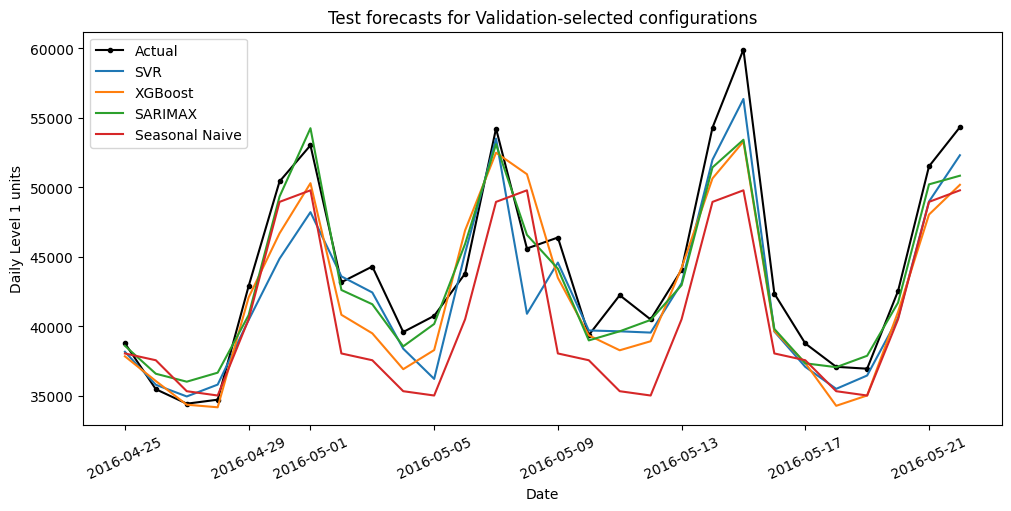

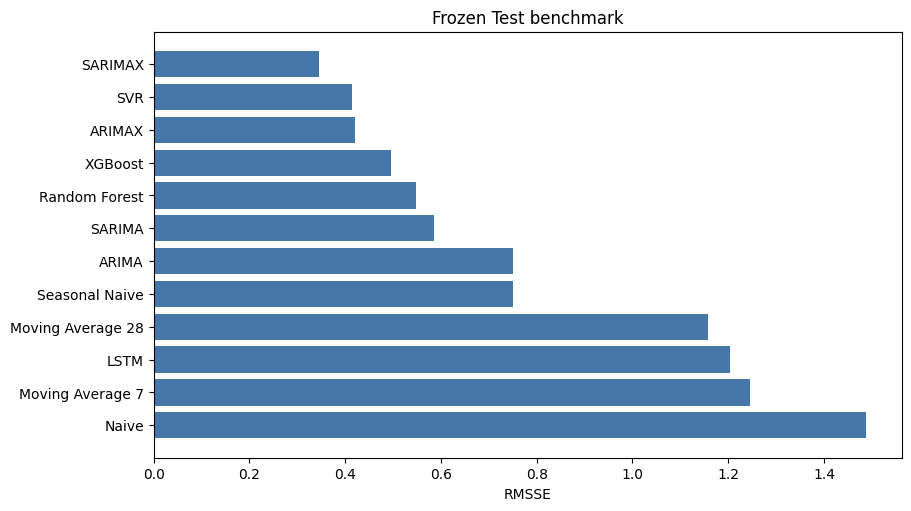

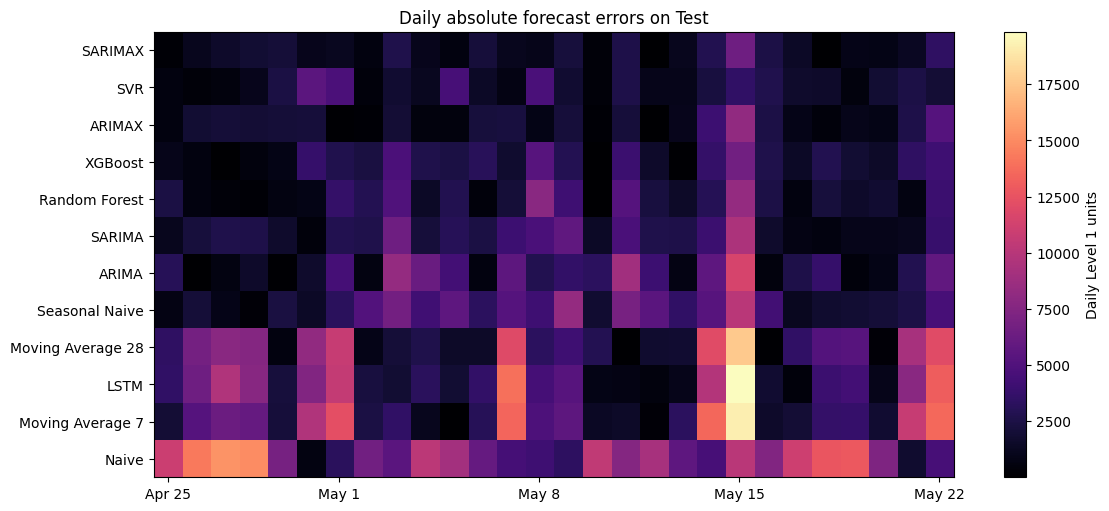

FINAL TEST CHECK PASSED
Configurations 12 | forecast rows 336 | saved learned models 8
Protocol SHA256 25a4a27e2909fb7415a616405d6707ef66c64461db7bab9f688d772536c5b5c6
Download /kaggle/working/09_final_test_results.zip


In [12]:
fig_forecast,ax = plt.subplots(figsize=(10,5),layout='constrained')
ax.plot(pd.to_datetime(test_frame['date']),test_frame['total_sales'],color='black',marker='o',
        markersize=3,label='Actual')
plot_ids = list(FROZEN_PROTOCOL['plot_models_selected_before_test'])
if 'seasonal_naive_7' not in plot_ids:
    plot_ids.append('seasonal_naive_7')
for cid in plot_ids:
    p = evaluated[evaluated['config_id'].eq(cid)]
    ax.plot(pd.to_datetime(p['date']),p['prediction'],label=p['model'].iloc[0])
ax.set(title='Test forecasts for Validation-selected configurations',xlabel='Date',ylabel='Daily Level 1 units')
ax.legend()
ax.tick_params(axis='x',rotation=25)
plt.show()

fig_scores,ax = plt.subplots(figsize=(9,5),layout='constrained')
labels = test_metrics['model'].where(test_metrics['model'].ne('Moving Average'),
                                    test_metrics['config_id'].str.replace('moving_average_','Moving Average '))
ax.barh(labels.iloc[::-1],test_metrics['rmsse'].iloc[::-1],color='#4776a8')
ax.set(title='Frozen Test benchmark',xlabel='RMSSE')
plt.show()

ordered_ids = test_metrics['config_id'].tolist()
matrix = np.vstack([evaluated[evaluated['config_id'].eq(cid)]['absolute_error'] for cid in ordered_ids])
fig_heatmap,ax = plt.subplots(figsize=(11,5),layout='constrained')
image = ax.imshow(matrix,aspect='auto',cmap='magma')
ax.set_yticks(range(12),labels)
ax.set_xticks([0,6,13,20,27],['Apr 25','May 1','May 8','May 15','May 22'])
ax.set_title('Daily absolute forecast errors on Test')
fig_heatmap.colorbar(image,ax=ax,label='Daily Level 1 units')
plt.show()

tables = {
    'final_development_selection.csv':pd.DataFrame(DEVELOPMENT_SELECTION),
    'final_fit_log.csv':pd.DataFrame(fit_log),
    'final_test_metrics.csv':test_metrics,
    'final_error_groups.csv':error_groups,
    'final_statistical_parameters.csv':pd.DataFrame(statistical_parameters),
    'final_lstm_fit_log.csv':pd.DataFrame(fit_rows),
    'final_lstm_learning_curves.csv':pd.DataFrame(curve_rows),
}
exported_paths = [freeze_path,*exported_model_paths,sealed_path]
for name,table in tables.items():
    path = table_dir/name
    table.to_csv(path,index=False)
    exported_paths.append(path)
evaluation_path = prediction_dir/'final_test_predictions.csv'
evaluated.to_csv(evaluation_path,index=False)
exported_paths.append(evaluation_path)
for name,figure in [('final_test_forecasts.png',fig_forecast),('final_test_metrics.png',fig_scores),
                    ('final_test_error_heatmap.png',fig_heatmap)]:
    path = figure_dir/name
    figure.savefig(path,dpi=300)
    exported_paths.append(path)
versions = {name:metadata.version(name) for name in
            ['numpy','pandas','scipy','scikit-learn','statsmodels','joblib','matplotlib']}
versions.update(torch=str(torch.__version__),xgboost=xgb.__version__)
manifest = {'protocol_sha256':PROTOCOL_SHA256,'training_days':ORIGIN,'models':model_records,
            'versions':versions,'forecast_sha256':SEALED_FORECAST_SHA256}
manifest_path = artifact_dir/'final_models_manifest.json'
manifest_path.write_text(json.dumps(manifest,indent=2),encoding='utf-8')
exported_paths.append(manifest_path)
report = {
    'status':'PASS','created_utc':datetime.now(timezone.utc).isoformat(),'python':platform.python_version(),
    'versions':versions,'protocol_sha256':PROTOCOL_SHA256,'forecast_sha256':SEALED_FORECAST_SHA256,
    'origin_day':ORIGIN,'forecast_rows':len(forecasts),'configuration_count':len(test_metrics),
    'rmsse_scale':RMSSE_SCALE,'rmsse_scale_history':'Train+Validation, 1913 observed days',
    'label_access':'Test covariates before fitting, Test sales after forecasts were sealed',
    'data_inventory':input_inventory,'pretest_selected_model':FROZEN_PROTOCOL['selected_before_test'],
    'metrics':test_metrics.to_dict('records'),'elapsed_seconds':perf_counter()-RUN_STARTED,
    'files':[path.relative_to(output_dir).as_posix() for path in exported_paths],
}
report_path = artifact_dir/'final_run_report.json'
report_path.write_text(json.dumps(report,indent=2),encoding='utf-8')
exported_paths.append(report_path)
zip_path = output_dir/'09_final_test_results.zip'
with ZipFile(zip_path,'w',compression=ZIP_DEFLATED) as archive:
    for path in exported_paths:
        archive.write(path,path.relative_to(output_dir).as_posix())
with ZipFile(zip_path) as archive:
    require(archive.testzip() is None and len(archive.namelist())==23,'Incomplete Test results package.')
print('FINAL TEST CHECK PASSED')
print(f'Configurations {len(test_metrics)} | forecast rows {len(forecasts)} | saved learned models {len(exported_model_paths)}')
print(f'Protocol SHA256 {PROTOCOL_SHA256}')
print(f'Download {zip_path}')